# Experiment 1: Time and Frequency Domain, and the Pendulum
**CSAI4014 AISR Laboratory** | Name: `<Suhani Baderia>` | SAP ID: `<500119327>` | Batch: `<4>`

This notebook runs top to bottom on a fresh kernel. Every figure is saved to `figs/` and every
observation table to `tables/`, ready to paste into the report.

**Parts**
1. Build a multi-tone signal and look at it in the time domain.
2. One-sided amplitude spectrum (FFT) with labelled peaks; set vs measured values.
3. Spectral leakage when the record length is T = 1.7 s.
4. Aliasing: a 5 Hz sine sampled at 8 Hz.
5. The nonlinear pendulum: damping, phase portrait, period vs initial amplitude.

In [2]:
import os
import platform
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
from scipy.special import ellipk

os.makedirs("figs", exist_ok=True)
os.makedirs("tables", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.3})

print("Python    :", platform.python_version())
print("NumPy     :", np.__version__)
print("SciPy     :", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)
print("OS / CPU  :", platform.platform(), "/", platform.processor() or platform.machine())

Python    : 3.10.0
NumPy     : 2.2.6
SciPy     : 1.15.3
Matplotlib: 3.10.9
OS / CPU  : Windows-10-10.0.26300-SP0 / Intel64 Family 6 Model 154 Stepping 3, GenuineIntel


## Part 1 – Sampling parameters and the constructed signal
The signal is a sum of three sines plus a DC offset:

$x(t) = A_0 + \sum_k A_k \sin(2\pi f_k t + \phi_k)$

Frequency resolution is $\Delta f = f_s / N = 1/T$; the Nyquist frequency is $f_s/2$.

In [3]:
fs = 200.0           # sampling frequency, Hz
T = 1.0              # record length, s
N = int(fs * T)      # number of samples
t = np.arange(N) / fs

DC = 0.5                                  # DC offset (V)
tones = [  # (frequency Hz, amplitude V, phase rad)
    (5.0, 1.0, 0.0),
    (12.0, 0.6, np.pi / 4),
    (23.0, 0.3, np.pi / 3),
]
x = DC + sum(A * np.sin(2 * np.pi * f * t + ph) for f, A, ph in tones)

sampling_table = [
    ("Sampling frequency f_s", f"{fs:.0f} Hz"),
    ("Record length T", f"{T:.2f} s"),
    ("Number of samples N", f"{N}"),
    ("Sampling interval dt = 1/f_s", f"{1e3 / fs:.1f} ms"),
    ("Frequency resolution df = 1/T", f"{1 / T:.3f} Hz"),
    ("Nyquist frequency f_s/2", f"{fs / 2:.0f} Hz"),
]
print(f"{'Parameter':<32}{'Value':>12}")
for k, v in sampling_table:
    print(f"{k:<32}{v:>12}")
np.savetxt("tables/T1_1_sampling_parameters.csv", np.array(sampling_table, dtype=object),
           fmt="%s", delimiter=",", header="Parameter,Value", comments="")

Parameter                              Value
Sampling frequency f_s                200 Hz
Record length T                       1.00 s
Number of samples N                      200
Sampling interval dt = 1/f_s          5.0 ms
Frequency resolution df = 1/T       1.000 Hz
Nyquist frequency f_s/2               100 Hz


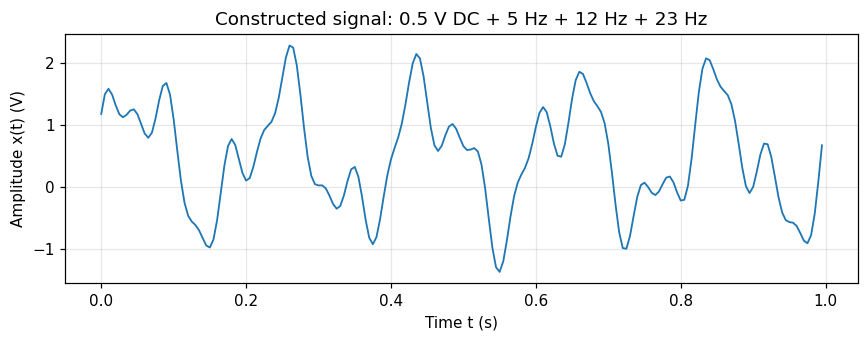

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.2))
show = t < 1.0
ax.plot(t[show], x[show], lw=1.2, color="tab:blue")
ax.set_xlabel("Time t (s)")
ax.set_ylabel("Amplitude x(t) (V)")
ax.set_title("Constructed signal: 0.5 V DC + 5 Hz + 12 Hz + 23 Hz")
fig.tight_layout()
fig.savefig("figs/fig1_1_signal_time_domain.png")
plt.show()

## Part 2 – One-sided amplitude spectrum
$X[k] = \sum_{n=0}^{N-1} x[n] e^{-j2\pi kn/N}$. One-sided amplitude: $|X[0]|/N$ for DC and
$2|X[k]|/N$ for $0<k<N/2$.

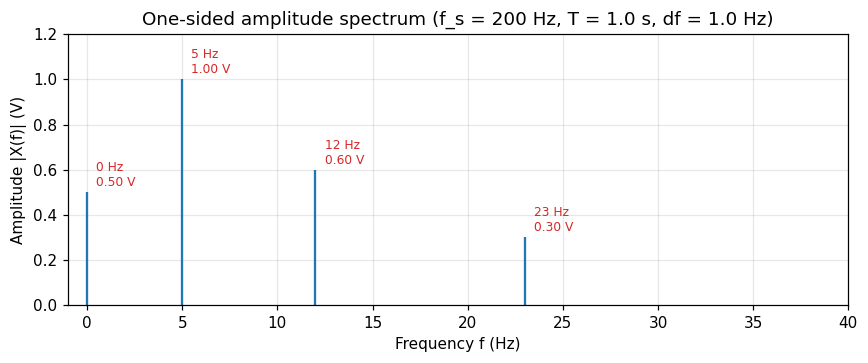

Component  Set f (Hz) Meas f (Hz) Set A (V) Meas A (V)  Error %
DC                0.0         0.0     0.500      0.500    -0.00
tone 1            5.0         5.0     1.000      1.000     0.00
tone 2           12.0        12.0     0.600      0.600    -0.00
tone 3           23.0        23.0     0.300      0.300     0.00


In [5]:
def one_sided_spectrum(sig, fs):
    n = len(sig)
    X = np.fft.rfft(sig)
    amp = np.abs(X) / n
    amp[1:] *= 2
    if n % 2 == 0:
        amp[-1] /= 2          # Nyquist bin is not doubled
    return np.fft.rfftfreq(n, 1 / fs), amp

f_axis, amp = one_sided_spectrum(x, fs)
peaks, _ = find_peaks(amp, height=0.1)
peaks = np.r_[0, peaks] if amp[0] > 0.1 else peaks     # include DC

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.stem(f_axis, amp, basefmt=" ", markerfmt=" ", linefmt="tab:blue")
for p in peaks:
    ax.annotate(f"{f_axis[p]:.0f} Hz\n{amp[p]:.2f} V", (f_axis[p], amp[p]),
                textcoords="offset points", xytext=(6, 4), fontsize=8, color="tab:red")
ax.set_xlim(-1, 40)
ax.set_ylim(0, 1.2)
ax.set_xlabel("Frequency f (Hz)")
ax.set_ylabel("Amplitude |X(f)| (V)")
ax.set_title(f"One-sided amplitude spectrum (f_s = {fs:.0f} Hz, T = {T} s, df = {1/T:.1f} Hz)")
fig.tight_layout()
fig.savefig("figs/fig1_2_amplitude_spectrum.png")
plt.show()

set_vals = [(0.0, DC)] + [(f, A) for f, A, _ in tones]
rows = []
print(f"{'Component':<10}{'Set f (Hz)':>11}{'Meas f (Hz)':>12}{'Set A (V)':>10}{'Meas A (V)':>11}{'Error %':>9}")
for (fset, Aset), p in zip(set_vals, peaks):
    err = 100 * (amp[p] - Aset) / Aset
    name = "DC" if fset == 0 else f"tone {len(rows)}"
    rows.append([name, fset, f_axis[p], Aset, amp[p], err])
    print(f"{name:<10}{fset:11.1f}{f_axis[p]:12.1f}{Aset:10.3f}{amp[p]:11.3f}{err:9.2f}")
np.savetxt("tables/T1_2_spectrum_set_vs_measured.csv", np.array(rows, dtype=object), fmt="%s",
           delimiter=",", header="Component,Set f (Hz),Measured f (Hz),Set A (V),Measured A (V),Error %",
           comments="")

## Part 3 – Spectral leakage at T = 1.7 s
With T = 1.7 s, $\Delta f = 0.588$ Hz. 5 Hz, 12 Hz and 23 Hz are **not** integer multiples of
$\Delta f$, so the record does not hold a whole number of cycles. The energy spreads into
neighbouring bins and the peak height drops (worst case about 36 % for a rectangular window).
A Hann window reduces the side lobes at the cost of a wider main lobe.

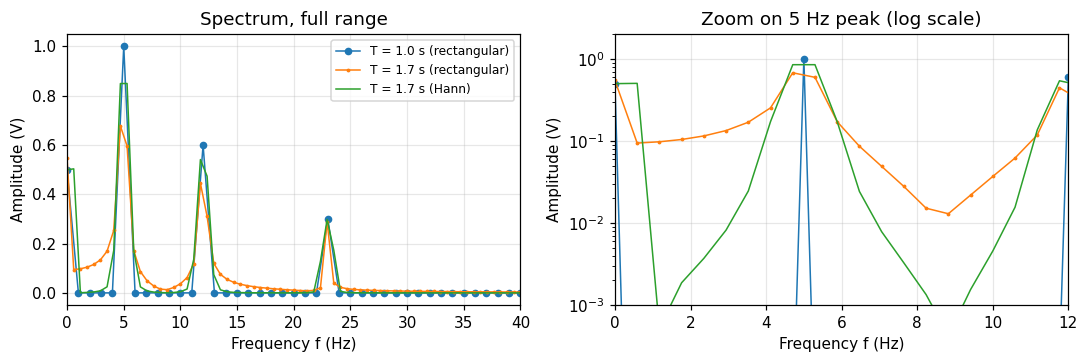

    5 Hz: nearest bin   4.706 Hz, rectangular peak 0.677 V (set 1.00 V, -32.3 %), Hann peak 0.850 V
   12 Hz: nearest bin  11.765 Hz, rectangular peak 0.445 V (set 0.60 V, -25.9 %), Hann peak 0.541 V
   23 Hz: nearest bin  22.941 Hz, rectangular peak 0.288 V (set 0.30 V, -3.9 %), Hann peak 0.298 V
df at T = 1.7 s: 0.5882 Hz


In [6]:
T_leak = 1.7
N_leak = int(fs * T_leak)
t_leak = np.arange(N_leak) / fs
x_leak = DC + sum(A * np.sin(2 * np.pi * f * t_leak + ph) for f, A, ph in tones)
f_l, amp_l = one_sided_spectrum(x_leak, fs)
win = np.hanning(N_leak)
f_h, amp_h = one_sided_spectrum(x_leak * win / win.mean(), fs)   # amplitude-corrected Hann

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
for a, (lo, hi) in zip(axs, [(0, 40), (0, 12)]):
    a.plot(f_axis, amp, "o-", ms=4, lw=1, label="T = 1.0 s (rectangular)")
    a.plot(f_l, amp_l, ".-", ms=3, lw=1, label="T = 1.7 s (rectangular)")
    a.plot(f_h, amp_h, "-", lw=1, label="T = 1.7 s (Hann)")
    a.set_xlim(lo, hi)
    a.set_xlabel("Frequency f (Hz)")
    a.set_ylabel("Amplitude (V)")
axs[1].set_yscale("log"); axs[1].set_ylim(1e-3, 2)
axs[0].set_title("Spectrum, full range"); axs[1].set_title("Zoom on 5 Hz peak (log scale)")
axs[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig("figs/fig1_3_spectral_leakage.png")
plt.show()

for f0, A, _ in tones:
    k = np.argmin(abs(f_l - f0))
    print(f"{f0:5.0f} Hz: nearest bin {f_l[k]:7.3f} Hz, rectangular peak {amp_l[k]:.3f} V "
          f"(set {A:.2f} V, {100*(amp_l[k]-A)/A:+.1f} %), Hann peak {amp_h[np.argmin(abs(f_h-f0))]:.3f} V")
print(f"df at T = 1.7 s: {fs / N_leak:.4f} Hz")

## Part 4 – Aliasing: a 5 Hz sine sampled at 8 Hz
Nyquist requires $f_s > 2f = 10$ Hz. At $f_s = 8$ Hz the samples are identical to those of a
sine at $|f - f_s| = 3$ Hz (with inverted phase). We measure the aliased frequency from the FFT of
the samples.

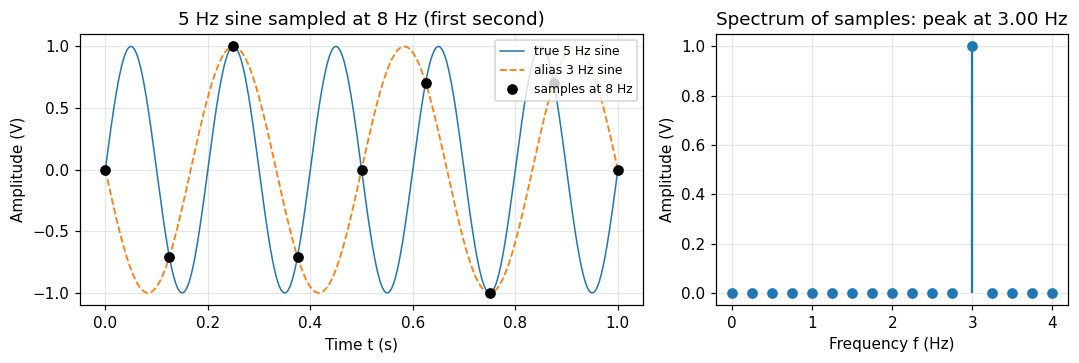

Predicted alias frequency: 3.00 Hz,  measured FFT peak: 3.00 Hz (resolution 0.25 Hz)


In [7]:
f_sig, fs_low, T_al = 5.0, 8.0, 4.0
t_cont = np.linspace(0, 1.0, 2000)
n_al = np.arange(int(fs_low * T_al))
t_s = n_al / fs_low
x_s = np.sin(2 * np.pi * f_sig * t_s)
f_alias_pred = abs(f_sig - fs_low * round(f_sig / fs_low))
fa_axis, amp_a = one_sided_spectrum(x_s, fs_low)
f_alias_meas = fa_axis[np.argmax(amp_a)]

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [1.6, 1]})
axs[0].plot(t_cont, np.sin(2 * np.pi * f_sig * t_cont), lw=1, label="true 5 Hz sine")
axs[0].plot(t_cont, -np.sin(2 * np.pi * f_alias_pred * t_cont), "--", lw=1.2,
            label=f"alias {f_alias_pred:.0f} Hz sine")
m = t_s <= 1.0
axs[0].plot(t_s[m], x_s[m], "ko", ms=6, label="samples at 8 Hz")
axs[0].set_xlabel("Time t (s)"); axs[0].set_ylabel("Amplitude (V)")
axs[0].set_title("5 Hz sine sampled at 8 Hz (first second)")
axs[0].legend(fontsize=8, loc="upper right")
axs[1].stem(fa_axis, amp_a, basefmt=" ")
axs[1].set_xlabel("Frequency f (Hz)"); axs[1].set_ylabel("Amplitude (V)")
axs[1].set_title(f"Spectrum of samples: peak at {f_alias_meas:.2f} Hz")
fig.tight_layout()
fig.savefig("figs/fig1_4_aliasing.png")
plt.show()
print(f"Predicted alias frequency: {f_alias_pred:.2f} Hz,  measured FFT peak: {f_alias_meas:.2f} Hz "
      f"(resolution {fs_low/len(x_s):.2f} Hz)")

## Part 5 – The pendulum
Equation of motion of a damped pendulum (length L, viscous damping coefficient c in s⁻¹):

$\ddot\theta + c\,\dot\theta + \dfrac{g}{L}\sin\theta = 0$

Small-angle period $T_0 = 2\pi\sqrt{L/g}$. Exact undamped period for amplitude $\theta_0$:
$T = 4\sqrt{L/g}\,K(k)$ with $k = \sin(\theta_0/2)$ (complete elliptic integral of the first kind).

L = 1.0 m, g = 9.81 m/s^2  ->  T0 = 2.0061 s


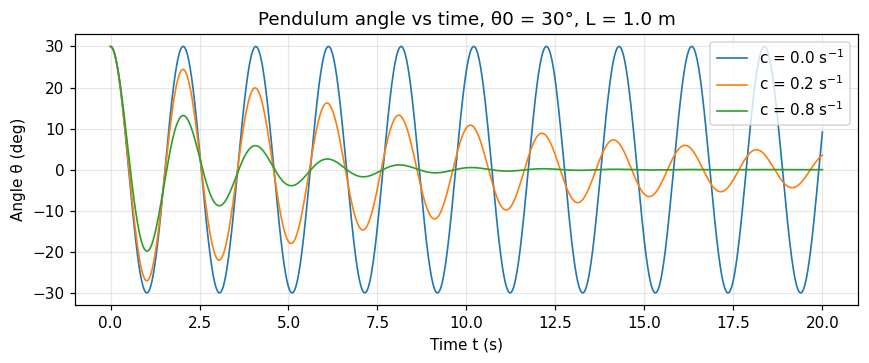

Damping coefficients used (1/s): [0.0, 0.2, 0.8]


In [8]:
g, L = 9.81, 1.0
T0 = 2 * np.pi * np.sqrt(L / g)
print(f"L = {L} m, g = {g} m/s^2  ->  T0 = {T0:.4f} s")

def pendulum(t, y, c):
    th, om = y
    return [om, -c * om - (g / L) * np.sin(th)]

t_end = 20.0
t_eval = np.linspace(0, t_end, 4001)
theta0 = np.deg2rad(30)
dampings = [0.0, 0.2, 0.8]          # c in 1/s: undamped, light, heavier
sols = {}
for c in dampings:
    sols[c] = solve_ivp(pendulum, (0, t_end), [theta0, 0.0], args=(c,), t_eval=t_eval,
                        rtol=1e-9, atol=1e-11)

fig, ax = plt.subplots(figsize=(8, 3.4))
for c in dampings:
    ax.plot(sols[c].t, np.rad2deg(sols[c].y[0]), lw=1.1, label=f"c = {c} s$^{{-1}}$")
ax.set_xlabel("Time t (s)"); ax.set_ylabel("Angle θ (deg)")
ax.set_title(f"Pendulum angle vs time, θ0 = 30°, L = {L} m")
ax.legend()
fig.tight_layout()
fig.savefig("figs/fig1_5_pendulum_damping.png")
plt.show()
print("Damping coefficients used (1/s):", dampings)

In [9]:
def measured_period(theta0_rad, n_periods=5):
    """Undamped period from successive downward zero crossings of theta."""
    def cross(t, y, c):
        return y[0]
    cross.direction = -1
    sol = solve_ivp(pendulum, (0, (n_periods + 1) * 4 * T0), [theta0_rad, 0.0], args=(0.0,),
                    events=cross, rtol=1e-10, atol=1e-12)
    tz = sol.t_events[0]
    return np.mean(np.diff(tz))

amps_deg = [5, 10, 20, 30, 45, 60, 90, 120, 150, 170]
period_rows = []
print(f"{'theta0 (deg)':>12}{'T meas (s)':>12}{'T exact (s)':>12}{'T/T0':>8}{'Series T (s)':>13}")
for a in amps_deg:
    th = np.deg2rad(a)
    Tm = measured_period(th)
    Tex = 4 * np.sqrt(L / g) * ellipk(np.sin(th / 2) ** 2)        # scipy uses m = k^2
    Tser = T0 * (1 + th**2 / 16 + 11 * th**4 / 3072)
    period_rows.append([a, Tm, Tex, Tm / T0, Tser])
    print(f"{a:12d}{Tm:12.4f}{Tex:12.4f}{Tm/T0:8.4f}{Tser:13.4f}")
period_rows = np.array(period_rows)
np.savetxt("tables/T1_3_period_vs_amplitude.csv", period_rows, fmt="%.5f", delimiter=",",
           header="theta0 (deg),T measured (s),T exact elliptic (s),T/T0,T series (s)", comments="")

theta0 (deg)  T meas (s) T exact (s)    T/T0 Series T (s)
           5      2.0070      2.0070  1.0005       2.0070
          10      2.0099      2.0099  1.0019       2.0099
          20      2.0215      2.0215  1.0077       2.0215
          30      2.0410      2.0410  1.0174       2.0410
          45      2.0863      2.0863  1.0400       2.0861
          60      2.1529      2.1529  1.0732       2.1522
          90      2.3678      2.3678  1.1803       2.3592
         120      2.7541      2.7541  1.3729       2.6943
         150      3.5351      3.5351  1.7622       3.2028
         170      4.8935      4.8935  2.4394       3.6665


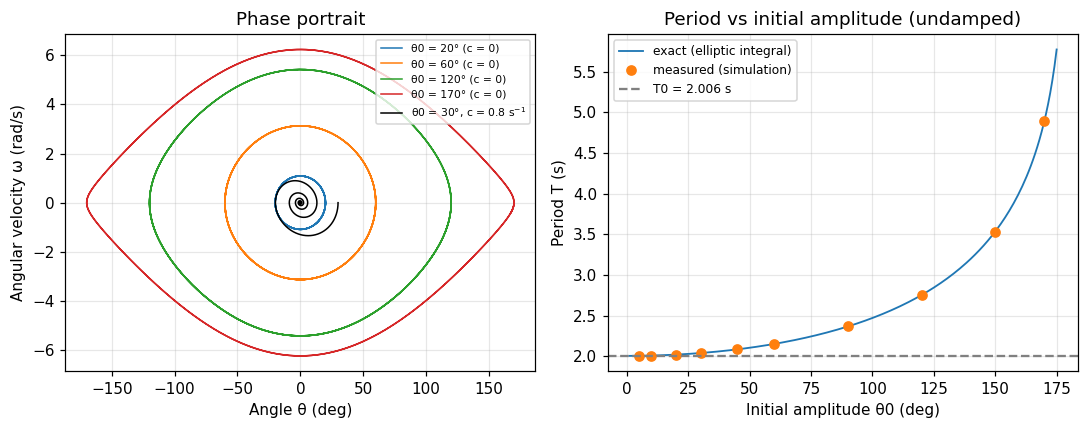

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for a in [20, 60, 120, 170]:
    s = solve_ivp(pendulum, (0, 2.5 * T0 * 2), [np.deg2rad(a), 0.0], args=(0.0,),
                  t_eval=np.linspace(0, 5 * T0, 2000), rtol=1e-9)
    axs[0].plot(np.rad2deg(s.y[0]), s.y[1], lw=1, label=f"θ0 = {a}° (c = 0)")
s = sols[0.8]
axs[0].plot(np.rad2deg(s.y[0]), s.y[1], lw=1, color="k", label="θ0 = 30°, c = 0.8 s$^{-1}$")
axs[0].set_xlabel("Angle θ (deg)"); axs[0].set_ylabel("Angular velocity ω (rad/s)")
axs[0].set_title("Phase portrait"); axs[0].legend(fontsize=7)

fine = np.linspace(1, 175, 200)
axs[1].plot(fine, 4 * np.sqrt(L / g) * ellipk(np.sin(np.deg2rad(fine) / 2) ** 2), lw=1.2,
            label="exact (elliptic integral)")
axs[1].plot(period_rows[:, 0], period_rows[:, 1], "o", label="measured (simulation)")
axs[1].axhline(T0, ls="--", color="gray", label=f"T0 = {T0:.3f} s")
axs[1].set_xlabel("Initial amplitude θ0 (deg)"); axs[1].set_ylabel("Period T (s)")
axs[1].set_title("Period vs initial amplitude (undamped)"); axs[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig("figs/fig1_6_phase_portrait_and_period.png")
plt.show()

## Summary of numbers for the report
Run the cell below and copy the printed values into Observations / Results.

In [11]:
print(f"Aliased peak frequency (5 Hz at 8 Hz): {f_alias_meas:.2f} Hz (predicted {f_alias_pred:.0f} Hz)")
print(f"T0 = 2*pi*sqrt(L/g) = {T0:.4f} s")
print(f"Damping coefficients used: {dampings} s^-1")
print(f"Period at 90 deg is {period_rows[amps_deg.index(90), 3]:.3f} x T0;"
      f" at 170 deg it is {period_rows[-1, 3]:.3f} x T0")

Aliased peak frequency (5 Hz at 8 Hz): 3.00 Hz (predicted 3 Hz)
T0 = 2*pi*sqrt(L/g) = 2.0061 s
Damping coefficients used: [0.0, 0.2, 0.8] s^-1
Period at 90 deg is 1.180 x T0; at 170 deg it is 2.439 x T0
